# Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual settings
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load Datasets

In [2]:
df = pd.read_csv("netflix_titles.csv")

In [3]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
df.shape

(8807, 12)

In [5]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


## Missing Values Analysis 

In [7]:
df.isnull().sum().sort_values(ascending=False)

director        2634
country          831
cast             825
date_added        10
rating             4
duration           3
show_id            0
type               0
title              0
release_year       0
listed_in          0
description        0
dtype: int64

## Duplicate Records Check

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

## Convert Date Columns Properly

In [10]:
df['date_added'] = pd.to_datetime(
    df['date_added'].str.strip(), format='%B %d, %Y', errors='coerce'
)

### Fix Misplaced Ratings (runtime value stored in rating)


In [11]:
bad_rating = df['rating'].str.contains(r'\d+\s*min', na=False)
df.loc[bad_rating, 'duration'] = df.loc[bad_rating, 'rating']
df.loc[bad_rating, 'rating'] = pd.NA
bad_rating.sum()

np.int64(3)

## Clean "duration" Column

In [12]:
df[['duration']].sample(10)

,duration
2049,117 min
6869,110 min
2202,84 min
1893,1 Season
6965,1 Season
7270,115 min
474,96 min
2921,2 Seasons
2264,151 min
1809,120 min


### Extract Numerical Value

In [13]:
df['duration_value']=df['duration'].str.extract('(\\d+)').astype(float)

### Extract Unit (min/Season)

In [14]:
df['duration_unit'] = df['duration'].str.extract('(min|Season|Seasons)')

## Handle Missing Values (impute, don't drop)

In [15]:
df.isna().sum()

show_id              0
type                 0
title                0
director          2634
cast               825
country            831
date_added          10
release_year         0
rating               7
duration             0
listed_in            0
description          0
duration_value       0
duration_unit        0
dtype: int64

In [16]:
df.describe(include="all")

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_value,duration_unit
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8800,8807,8807,8807,8807.000000,8807
unique,8807,2,8807,4528,7692,748,NaN,NaN,14,220,514,8775,NaN,2
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,NaN,NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope...",NaN,min
freq,1,6131,1,19,19,2818,NaN,NaN,3207,1793,362,4,NaN,6131
mean,NaN,NaN,NaN,NaN,NaN,NaN,2019-05-17 05:59:08.436967168,2014.180198,NaN,NaN,NaN,NaN,69.848530,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,2008-01-01 00:00:00,1925.000000,NaN,NaN,NaN,NaN,1.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2018-04-06 00:00:00,2013.000000,NaN,NaN,NaN,NaN,2.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2019-07-02 00:00:00,2017.000000,NaN,NaN,NaN,NaN,88.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,2020-08-19 00:00:00,2019.000000,NaN,NaN,NaN,NaN,106.000000,NaN
max,NaN,NaN,NaN,NaN,NaN,NaN,2021-09-25 00:00:00,2021.000000,NaN,NaN,NaN,NaN,312.000000,NaN


In [17]:
df.shape

(8807, 14)

In [18]:
df['director'] = df['director'].fillna("Not Specified")
df['cast'] = df['cast'].fillna("Not Specified")
df['country'] = df['country'].fillna("Unknown")
df['rating'] = df['rating'].fillna("Unrated")

### Final Data Validation

In [19]:
df.isna().sum()

show_id            0
type               0
title              0
director           0
cast               0
country            0
date_added        10
release_year       0
rating             0
duration           0
listed_in          0
description        0
duration_value     0
duration_unit      0
dtype: int64

In [20]:
df.describe(include="all")

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_value,duration_unit
count,8807,8807,8807,8807,8807,8807,8797,8807.000000,8807,8807,8807,8807,8807.000000,8807
unique,8807,2,8807,4529,7693,749,NaN,NaN,15,220,514,8775,NaN,2
top,s1,Movie,Dick Johnson Is Dead,Not Specified,Not Specified,United States,NaN,NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope...",NaN,min
freq,1,6131,1,2634,825,2818,NaN,NaN,3207,1793,362,4,NaN,6131
mean,NaN,NaN,NaN,NaN,NaN,NaN,2019-05-17 05:59:08.436967168,2014.180198,NaN,NaN,NaN,NaN,69.848530,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,2008-01-01 00:00:00,1925.000000,NaN,NaN,NaN,NaN,1.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2018-04-06 00:00:00,2013.000000,NaN,NaN,NaN,NaN,2.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2019-07-02 00:00:00,2017.000000,NaN,NaN,NaN,NaN,88.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,2020-08-19 00:00:00,2019.000000,NaN,NaN,NaN,NaN,106.000000,NaN
max,NaN,NaN,NaN,NaN,NaN,NaN,2021-09-25 00:00:00,2021.000000,NaN,NaN,NaN,NaN,312.000000,NaN


# Exploratory Data Analysis (EDA)

### Dashboard Theme Setup

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (12, 6)

## Content Type Distribution (KPI-Level Chart)

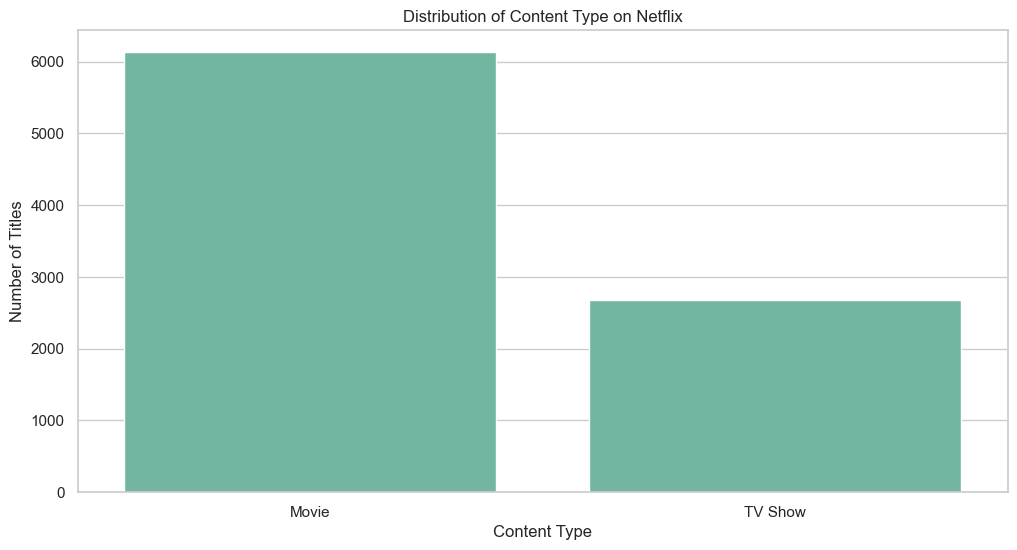

In [22]:
sns.countplot(data=df, x='type')
plt.title("Distribution of Content Type on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

## Content Growth Over Time (Trend Analysis)

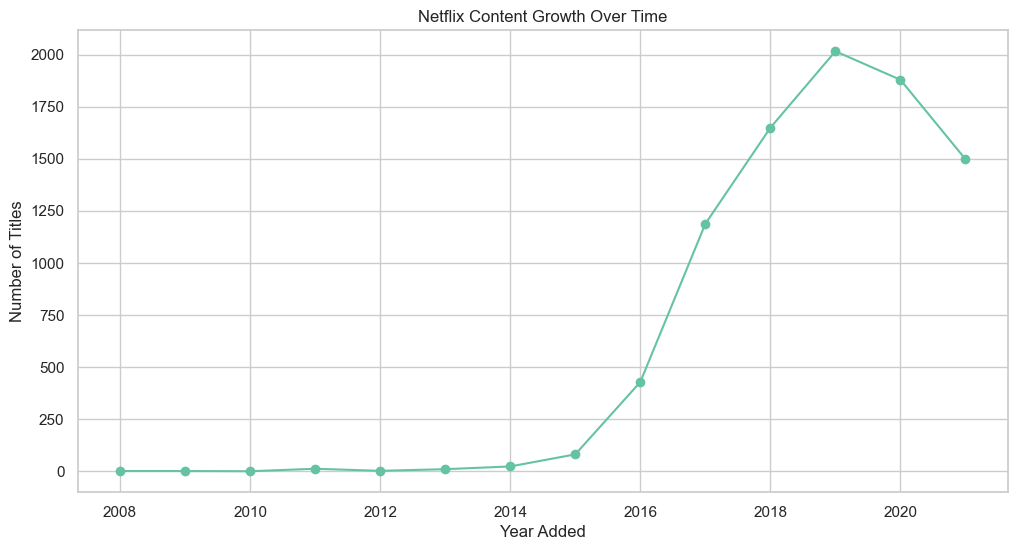

In [23]:
df['year_added'] = df['date_added'].dt.year

content_growth = df.groupby('year_added').size()

content_growth.plot(kind='line', marker='o')
plt.title("Netflix Content Growth Over Time")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.show()


## Top Content Producing Countries (Geo Strategy)

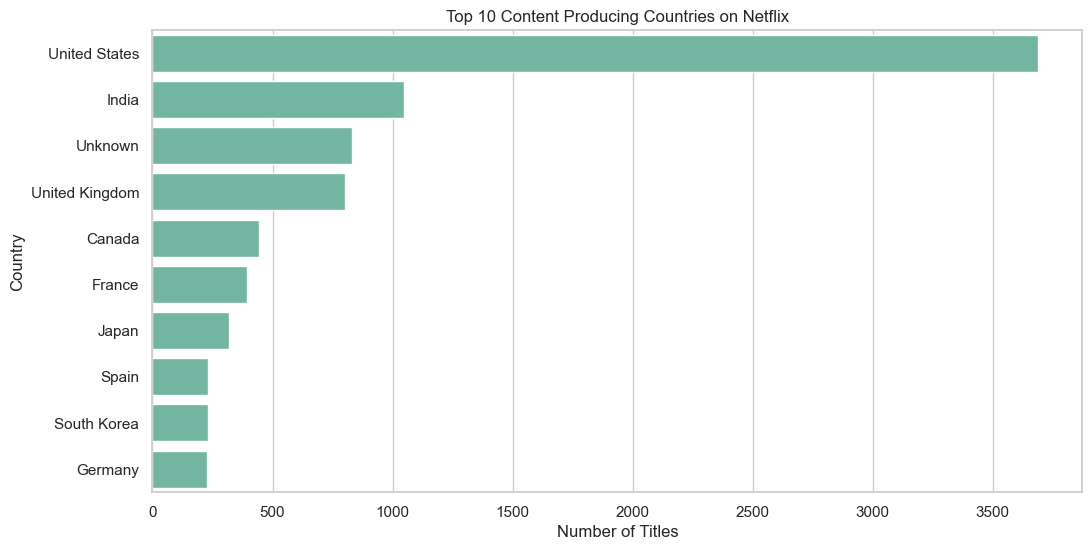

In [24]:
top_countries = (
    df['country']
    .str.split(', ')
    .explode()
    .value_counts()
    .head(10)
)

sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Content Producing Countries on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()


## Movies Duration Distribution (Operational Insight)

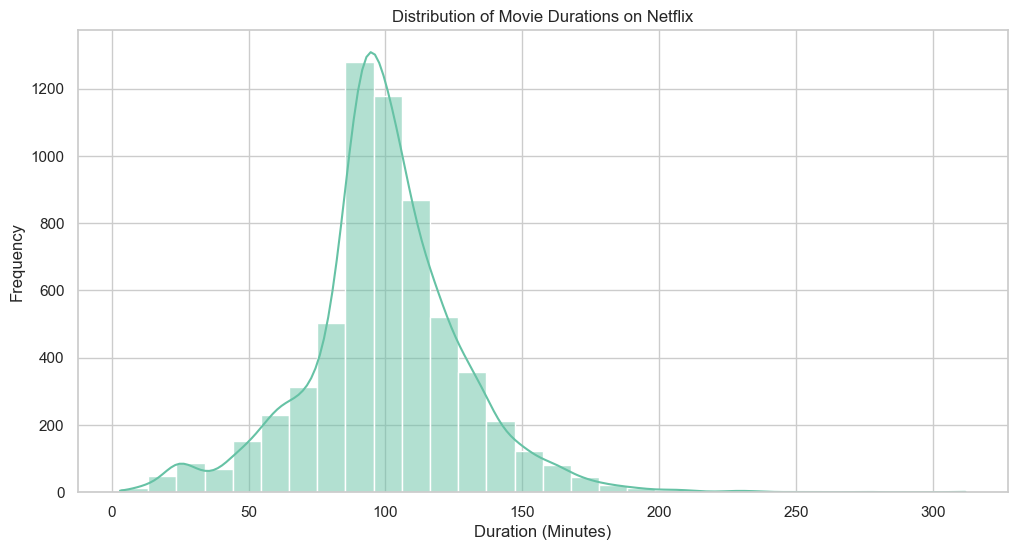

In [25]:
movies = df[df['type'] == 'Movie']

sns.histplot(movies['duration_value'], bins=30, kde=True)
plt.title("Distribution of Movie Durations on Netflix")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Frequency")
plt.show()


## TV Shows Seasons Distribution (Retention Focus)

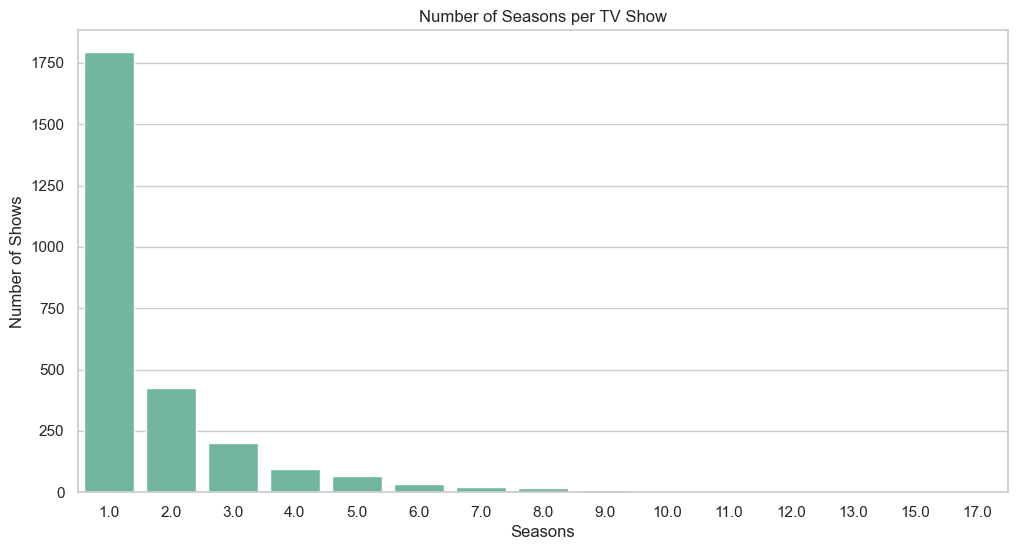

In [26]:
tv_shows = df[df['type'] == 'TV Show']

sns.countplot(x=tv_shows['duration_value'])
plt.title("Number of Seasons per TV Show")
plt.xlabel("Seasons")
plt.ylabel("Number of Shows")
plt.show()


## Top Genres on Netflix (Content Strategy)

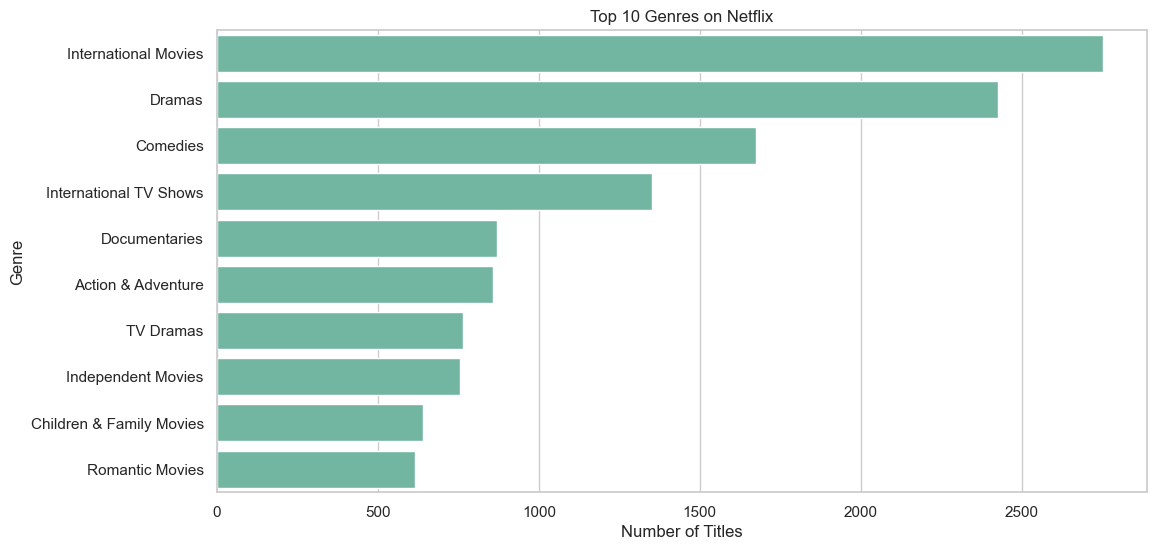

In [27]:
top_genres = (
    df['listed_in']
    .str.split(', ')
    .explode()
    .value_counts()
    .head(10)
)

sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.show()


## Rating Distribution

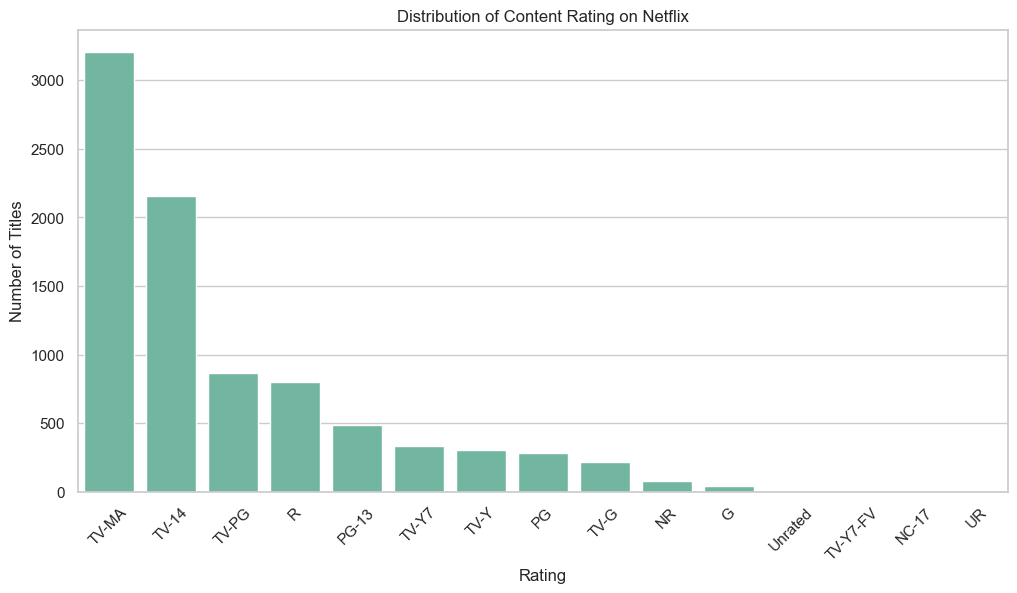

In [28]:
sns.countplot(data=df, x="rating", order=df['rating'].value_counts().index)
plt.title("Distribution of Content Rating on Netflix")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()